# CMSE 201 Semester Project Proposal
Jay Reddy, Section 008

## Research Question
For any $n$ in an $n$-body molecular dynamics simulation of an arbitrary gas, at what combinations of temperature and pressure is the deviation of the ideal gas law from the real gas law deemed statistically significant? How can we find and approximate this with computational modeling? How can we asses the quality of our model using data analysis?

## Context Statement
The ideal gas law is most well known physical chemistry equations: $$PV = nRT,$$ where $P$ is pressure, $V$ is volume, $n$ is the number of moles of gas, $R$ is the gas constant, and $T$ is temperature. This equation is very helpful in solving for missing variable for some ideal gas. With this equation however, some large assumptions are made to create an ideal gas. An ideal gas is assumed to have no particle-particle interactions, perfectly elastic collisions, and zero particle volume. Further, gasses that exhibit ideal properties only occur at relatively low pressure and high temperature. This is because the particle particle interaction is minimized - low pressures indicate large average distances between particles, and high temperatures mean particles generally move too fast for interactions to be significant. However, when you study gasses that don't prescribe to these conditions, particles are subject to short range repulsive forces and long range attractive forces that skew experimentally derived values from those theoretically calculated by the Ideal gas law. This is when the real gas law becomes helpful: $$\left( P + \frac{a n^{2}}{V^{2}} \right) \left( V - nb \right) = nRT,$$ where $a$ is the pressure correction constant, and $b$ is the volume correction constant. Now we can get relativistic outputs when our gasses are dense and slow. However, when only working in theory, you cannot tell when exactly a gas will behave ideally or not based on the conditions, as the real gas law requires the use of the experimentally derived constants $a$ and $b$. Hopefully and eventually, with this program, you can estimate the exact temperature and pressure falloff for the ideal gas law. Some assumptions have been made. Main particle interactions happen via Lennard-Jones 16-6 Potential (mathematical approximation for van-der-waal's forces). The program as of right now has elastic wall collisions (subject to change). The units are currently dimensionless. Hopefully by submission date it will realistically model (within some degree of error, of course) a table of gasses with estimations for multi-gas systems (using statistical and geometric mean calculations for the Lennard-Jones potential sigma and epsilon constants). Model will hopefully model and output ideal gas law deviations, as well as temperature, pressure, and particle speed distributions (Maxwell-Boltzmann distributions) or combinations of statistical output.

## Current Resource List
All of the resources I have used so far are listed below (list is subject to change). I apologize, they are not commented and organized. Note: This includes two questions I asked on Stack Overflow with responses I have implemented into the current version of my code. All code is subject to change. 

- https://pythoninchemistry.org/sim_and_scat/intro
- https://courses.grainger.illinois.edu/mse485/fa2019/Homework2.html
- https://tutorial.pyvista.org/tutorial/00_intro/index.html
- https://docs.pytorch.org/docs/2.14/index.html
- https://www.youtube.com/watch?v=iSEAidM-DDI
- https://www.youtube.com/watch?v=ipRnvs7_CxA
- https://www.youtube.com/watch?v=ChQbBqndwIA
- https://en.wikipedia.org/wiki/Verlet_integration
- https://en.wikipedia.org/wiki/Lennard-Jones_potential
- https://github.com/pyvista/pyvista/discussions/3107
- https://physics.stackexchange.com/questions/440212/ball-bouncing-elastically-off-a-wall-with-no-slipping
- http://wwwcourses.sens.buffalo.edu/ce407/notes/ce407_notes_Lennard_Jones.pdf
- https://wwwcourses.sens.buffalo.edu/ce407/notes/ce407_notes_Lennard_Jones.pdf
- https://mattermodeling.stackexchange.com/questions/4845/how-to-create-a-lookup-table-of-%CF%B5-and-%CF%83-values-for-lennard-jones-potentials
- https://physics.stackexchange.com/questions/159674/velocity-maxwell-boltzmann-distribution-for-dummies
- https://stackoverflow.com/questions/82831/how-do-i-check-whether-a-file-exists-without-exceptions
- https://flaviocopes.com/python-create-empty-file/
- https://stackoverflow.com/questions/40416072/reading-a-file-using-a-relative-path-in-a-python-project
- https://stackoverflow.com/questions/5137497/find-the-current-directory-and-files-directory
- https://stackoverflow.com/questions/67196382/str-object-has-no-attribute-exists-is-file
- https://stackoverflow.com/questions/80014777/how-can-i-sum-elements-of-a-tensor-based-on-a-condition-of-one-out-of-two-values
- https://stackoverflow.com/questions/80015428/pyvista-plotting-running-slowly-resetting-box-size-and-causing-collisions

## Current Model: V1
Below is the current iteration of my model. Please note this was started much earlier in this semester and is the sum of a few weeks of work.
Currently, no data analysis is included, only a rough particle simulation or tensor printout. 

FileNotFoundError: [WinError 2] The system cannot find the file specified

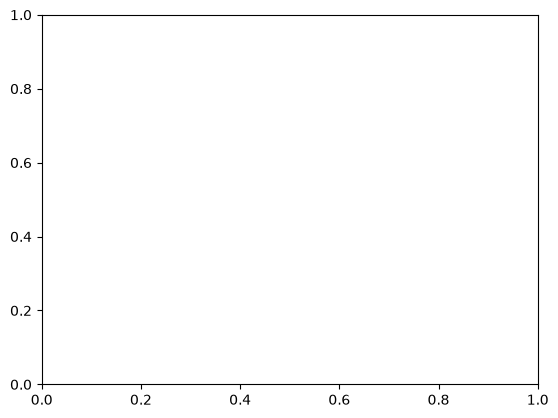

In [4]:
# ===== PACKAGE IMPORT ===== #
import matplotlib.pyplot as plt   
import matplotlib.animation as animation 
from matplotlib.animation import FFMpegWriter 
import numpy as np                  
import pyvista as pv                
import torch    
import os
import os.path       
import ipywidgets
import time

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu') 

# ===== SIMULATION CHOICE ===== #
#       make one or the other True       #
tensor_printout = False          # prints a tensor for every print_steps
visualization = False            # PyVista 3d visualization (heavily depended on CPU multithreading capability and for higher n_part, GPU capability)
velocity_distribution = True    

# ===== FILE NAMING AND CREATION ===== #
#       pyvista       #
pv_filename = 'MD_visualization.mp4'    # DO NOT CHANGE .MP4

#       matplotlib       #
plt_filename = 'test.mp4'        # DO NOT CHANGE .MP4

#       file checks + auto creation       #
if visualization == True:
    if os.path.exists(pv_filename) == False:
        open(pv_filename, 'x').close()

if velocity_distribution == True:
    if os.path.exists(plt_filename) == False:
        open(plt_filename, 'x').close()

# ===== DEFINING PARTICLES ===== #      
n_part = 100                     # number of particles
box_size = 50                    # box size

r = torch.rand((n_part,3)).to(device) * box_size                        # NEEDS UNITS AND OPTIMIZATION (multiplication increases spread of starting positions within box size)
v = torch.normal(mean=500, std = 50, size = (n_part,3)).to(device)      # mean = velocity, std = distribution
a = torch.zeros((n_part,3)).to(device)                                  
new_a = 0                                                               # for the very first verlet integration loop

ids = torch.arange(n_part)
ids_pairs = torch.combinations(ids, 2).to(device)       

dt = 0.0005                                                             # time step between frames
n_steps = 100                                                          # number of frames calculated
print_steps = 10                                                        # prints every n steps in tensor_printout

# constants
sig = 1                                                                 # dimensionless (force cutoff)
ep = 1                                                                  # dimensionless (potential well depth)
inv_mass = 1                                                            # dimensionless (for a=F/m)

# ===== POSITION - DISTANCE PAIRS ===== #
def comp_dim_pairs(r, dim):
    pairs =torch.diff(torch.combinations(r[:, dim],2).to(device), axis = 1).ravel().to(device)
    return pairs

def comp_dpairs(dx_pairs, dy_pairs, dz_pairs):
    d_pairs = torch.sqrt(dx_pairs**2 + dy_pairs**2 + dz_pairs**2).to(device)
    return d_pairs

def comp_dpairs_simp(r):
    dpairs_simp = comp_dpairs(comp_dim_pairs(r, 0), comp_dim_pairs(r, 1), comp_dim_pairs(r, 2)).to(device)
    return dpairs_simp

# ===== FORCE CALCULATIONS VIA NEGATIVE GRADIENT OF THE LENNARD-JONES POTENTIAL ===== #
def comp_force_pairs(r, ep, sig):
    F_r_n = ((24 * ep) / comp_dpairs_simp(r)) * (2 * ( sig / comp_dpairs_simp(r)) ** 12 - ( sig / comp_dpairs_simp(r)) ** 6).to(device)
    return F_r_n

# ===== UNIT VECTOR PAIR CALCULATION ===== #
def unit_vec_pairs(r): 
    unit_vec_pairs =torch.stack((comp_dim_pairs(r, 0)/comp_dpairs_simp(r), comp_dim_pairs(r, 1)/comp_dpairs_simp(r), comp_dim_pairs(r, 2)/comp_dpairs_simp(r)), dim = 1).to(device)
    return unit_vec_pairs

# ===== SCALAR TO VECTOR FORCE ===== #
def vec_force(r, ep, sig):
    vec_force = comp_force_pairs(r, ep, sig)[:, None] * unit_vec_pairs(r)
    return vec_force

# ===== SUM OF FORCES PER PARTICLE ===== #
def comp_F_sum(n_part, ids_pairs, r, ep, sig):
    F_sum = torch.zeros(n_part, 3).to(device)
    F_sum.index_add_(0, ids_pairs[:,0], vec_force(r, ep, sig))
    F_sum.index_add_(0, ids_pairs[:,1], vec_force(r, ep, sig), alpha = -1)
    return F_sum

# ===== WALL DETECTION ===== #
def check_wall_coll(r, v, dim, low, high):
    out = (r[:, dim] < low) | (r[:, dim] > high)
    v[:, dim] = torch.where(out, -v[:, dim], v[:, dim])
    r[:, dim] = r[:, dim].clamp(low, high)
    return r, v

# ===== FINAL POSITION, VELOCITY, ACCELERATION FUNCTIONS ===== #
def comp_a(n_part, ids_pairs, r, ep, sig, inv_mass):
    new_a = (comp_F_sum(n_part, ids_pairs, r, ep, sig) * inv_mass)
    return new_a

def comp_v(v, a, new_a, dt):                
    new_v = v + (a + new_a) * dt * 0.5                                              # average velocities over time steps
    return new_v

def comp_r(r, v, a, dt):
    new_r = r + (v * dt) + (a * dt * dt * 0.5)      
    return new_r

def comp_scl_v(v):                                                                  # scalar velocities for distribution
    scl_v = torch.sqrt(v[:,0]**2 + v[:,1]**2 + v[:, 2]**2) 
    return scl_v

def run_it_down(r, v, dt, a, n_part, ids_pairs, ep, sig, inv_mass, box_size):
    new_r = comp_r(r, v, a, dt)                                                     # verlet integration prevents KE creep
    new_a = comp_a(n_part, ids_pairs, new_r, ep, sig, inv_mass)
    new_v = comp_v(v, a, new_a, dt)
    new_r, new_v = check_wall_coll(new_r, new_v, 0, 0, box_size)                    # wall collisions and return unpacking
    new_r, new_v = check_wall_coll(new_r, new_v, 1, 0, box_size)
    new_r, new_v = check_wall_coll(new_r, new_v, 2, 0, box_size)
    r = new_r
    v = new_v
    a = new_a
    return r, v, a

# ===== SIMULATION SETTINGS ===== #
#       pyvista       #
pl = pv.Plotter(off_screen=True)                
pl.open_movie(pv_filename)
cloud = pv.PolyData(r.cpu().numpy())
pl.add_mesh(cloud, scalars = r[:, 0], cmap="grey", point_size=5, render_points_as_spheres=True)      # CHANGE PARTICLE VISUAL ATTRIBUTES HERE
pl.show_grid(bounds=(0, box_size, 0, box_size, 0, box_size), color="grey")          # BOUNDS ARGUMENTS 
pl.camera_position = [(200, 200, 200), (0, 0, 25), (0, 0, 1)]                     # CHANGE CAMERA POSITIONING HERE

#       matplotlib       #
fps = 60
writer = FFMpegWriter(fps=fps)
fig, ax = plt.subplots()

# ===== LOGIC TREE ===== #
if tensor_printout == True:
    for i in range(n_steps):
        if i == 0:
            a = comp_a(n_part, ids_pairs, r, ep, sig, inv_mass)
        if i % print_steps == 0:
            r, v, a = run_it_down(r, v, dt, a, n_part, ids_pairs, ep, sig, inv_mass, box_size)
            print("position", r)
            print("velocity", v)
            print("acceleration", a)
        if visualization == True:
            for j in range(n_steps):
                r, v, a = run_it_down(r, v, dt, a, n_part, ids_pairs, ep, sig, inv_mass, box_size)
                cloud.points = r.cpu().numpy()
                pl.write_frame()
            if velocity_distribution == True:
                with writer.saving(fig, plt_filename, 100):
                    for k in range(n_steps):
                        r, v, a = run_it_down(r, v, dt, a, n_part, ids_pairs, ep, sig, inv_mass, box_size)
                        scl_v = comp_scl_v(v)
    
                        ax.clear()
                        plt.hist(scl_v)
                        writer.grab_frame()
    pl.close()
if tensor_printout == False:
    if visualization == True:
        for j in range(n_steps):
            r, v, a = run_it_down(r, v, dt, a, n_part, ids_pairs, ep, sig, inv_mass, box_size)
            cloud.points = r.cpu().numpy()
            pl.write_frame()
        if velocity_distribution == True:
                    with writer.saving(fig, plt_filename, 100):
                        for k in range(n_steps):
                            r, v, a = run_it_down(r, v, dt, a, n_part, ids_pairs, ep, sig, inv_mass, box_size)
                            scl_v = comp_scl_v(v)
        
                            ax.clear()
                            plt.hist(scl_v)
                            writer.grab_frame()
    pl.close()  
if visualization == False:
    if velocity_distribution == True:
        with writer.saving(fig, plt_filename, 100):
            for k in range(n_steps):
                r, v, a = run_it_down(r, v, dt, a, n_part, ids_pairs, ep, sig, inv_mass, box_size)
                scl_v = comp_scl_v(v)

                ax.clear()
                plt.hist(scl_v)
                writer.grab_frame()
    else:
        print("ERROR - No Simulation Output Selected")
        print("Please make at least one of \"tensor_printout,\" \"visualization,\" or \"velocity_distribution\" == True")

# def hist_func(scl_v):
#     plt.cla()
#     r, v, a = run_it_down(r, v, dt, a, n_part, ids_pairs, ep, sig, inv_mass, box_size)
#     svl_v = comp_scl_v(v)
#     plt.hist(scl_v)